# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.

Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial. 
But are they?

4. Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

1. Check out the data set `heart_failure` and appropriately clean it.

In [3]:
import pandas as pd


df = pd.read_csv("data/heart_failure/heart_failure_clinical_records_dataset.csv")
print("Shape:", df.shape)
print(df.isna().sum())
print("Data types", df.dtypes)
df = df.dropna()
df.head()
# The dataset has 299 rows and 13 columns with 0 missing values in any column.
# The variables are numeric (int64 or float64)
#The binary columns  like anaemia, diabetes, sex, and smoking are coded binary 0 or 1.
#made sure with the dropna 

Shape: (299, 13)
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64
Data types age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


array([[<Axes: title={'center': 'age'}>,
        <Axes: title={'center': 'anaemia'}>,
        <Axes: title={'center': 'creatinine_phosphokinase'}>,
        <Axes: title={'center': 'diabetes'}>],
       [<Axes: title={'center': 'ejection_fraction'}>,
        <Axes: title={'center': 'high_blood_pressure'}>,
        <Axes: title={'center': 'platelets'}>,
        <Axes: title={'center': 'serum_creatinine'}>],
       [<Axes: title={'center': 'serum_sodium'}>,
        <Axes: title={'center': 'sex'}>,
        <Axes: title={'center': 'smoking'}>,
        <Axes: title={'center': 'time'}>],
       [<Axes: title={'center': 'DEATH_EVENT'}>, <Axes: >, <Axes: >,
        <Axes: >]], dtype=object)

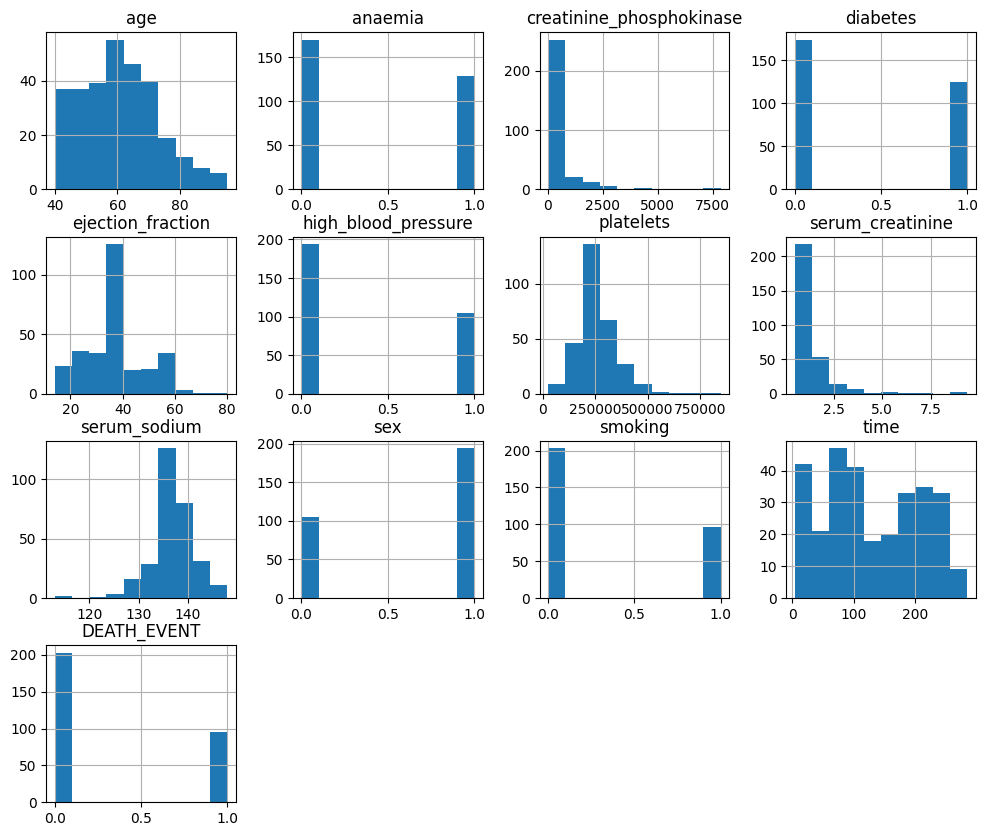

In [4]:
df.hist(figsize=(12, 10))
#for fun just wanted to see)

2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.

In [10]:
from sklearn.model_selection import train_test_split

eval_x_raw = df.drop(columns=['ejection_fraction'])
eval_y = df['ejection_fraction']

(x_train, x_test, y_train, y_test,) = train_test_split(eval_x_raw, eval_y, test_size=0.20, random_state=100)

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score

tree_model = DecisionTreeClassifier(max_depth=3, random_state=100)
tree_model.fit(x_train, y_train)

tree_preds_base = tree_model.predict(x_test)

print("Train Tree Accuracy:", round(tree_model.score(x_train, y_train), 4))
print("Test Tree Accuracy:", round(tree_model.score(x_test, y_test), 4))
print("Train Tree F1:", round(f1_score(y_train, tree_model.predict(x_train), average="weighted"), 4))
print("Test Tree F1:",round(f1_score(y_test, tree_preds_base, average="weighted"), 4))

Train Tree Accuracy: 0.2929
Test Tree Accuracy - test: 0.2333
Tree F1 - train: 0.2271
Tree F1 - test: 0.1447


In [ ]:
from sklearn.linear_model import LogisticRegression

lin_model = LogisticRegression(solver='saga', max_iter=10000)
lin_model.fit(x_train, y_train)

lin_preds_base = lin_model.predict(x_test)

print("Train Accuracy:", round(lin_model.score(x_train, y_train), 4))
print("Test Accuracy:", round(lin_model.score(x_test, y_test), 4))
print("Train Logistic F1:", round(f1_score(y_train, lin_model.predict(x_train), average="weighted"), 4))
print("Test Logistic F1:", round(f1_score(y_test, lin_preds_base, average="weighted"), 4))

Logistic Accuracy - train: 0.159
Logistic Accuracy - test: 0.1833
Logistic F1 - train: 0.0436
Logistic F1 - test: 0.0568


In [124]:
# Using random_state=100 for the 80/20 split and predicting ejection fraction.
# Both models have negative test R-squared values, so neither model predicted
# ejection fraction well on this test set.
# On the test set, the linear model performs slightly better:
# test R-squared = -0.1033 and test RMSE = 13.2709.
# The decision tree has test R-squared = -0.1473 and test RMSE = 13.5332.
# Both models perform better on the training data than on the test data,
# which could suggest overfitting.

3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
#not the best with forwards loops so if u guys want to change it to a loop than be my guest

In [ ]:
#101
(x_train_101, x_test_101, y_train_101, y_test_101,) = train_test_split(eval_x_raw, eval_y, test_size=0.20, random_state=101)

tree_101 = DecisionTreeClassifier(max_depth=3, random_state=100)
tree_101.fit(x_train_101, y_train_101)
tree_preds_101 = tree_101.predict(x_test)

lin_101 = LogisticRegression(solver='saga', max_iter=10000)
lin_101.fit(x_train_101, y_train_101)
lin_preds_101 = lin_101.predict(x_test)

print("Tree Train Accuracy:", round(tree_101.score(x_train_101, y_train_101), 4))
print("Tree Test Accuracy:", round(tree_101.score(x_test_101, y_test_101), 4))
print("Linear Train Accuracy:", round(lin_101.score(x_train_101, y_train_101), 4))
print("Linear Test Accuracy:", round(lin_101.score(x_test_101, y_test_101), 4))
print("Linear 101 coefs:", lin_101.coef_.round(4))

Tree Train Accuracy: 0.2887
Tree Test Accuracy: 0.2833
Linear Train Accuracy: 0.159
Linear Test Accuracy: 0.1833
Linear 101 coefs: [[-0.     -0.      0.     -0.     -0.     -0.     -0.      0.      0.
  -0.     -0.      0.    ]
 [ 0.      0.     -0.      0.     -0.     -0.     -0.      0.     -0.
  -0.     -0.      0.    ]
 [-0.     -0.     -0.      0.      0.     -0.      0.     -0.     -0.
  -0.     -0.      0.    ]
 [ 0.     -0.     -0.     -0.      0.      0.      0.      0.      0.
   0.     -0.      0.    ]
 [ 0.      0.      0.0001 -0.     -0.      0.      0.      0.      0.
  -0.     -0.      0.    ]
 [-0.      0.      0.0001  0.     -0.      0.     -0.     -0.     -0.
   0.     -0.     -0.    ]
 [-0.     -0.      0.0001 -0.     -0.      0.      0.      0.      0.
   0.      0.     -0.    ]
 [ 0.     -0.      0.0001  0.     -0.      0.      0.      0.      0.
   0.      0.      0.    ]
 [ 0.      0.     -0.0001 -0.     -0.      0.     -0.      0.     -0.
  -0.      0.     -0.  

In [149]:
#102
(x_train_102, x_test_102, y_train_102, y_test_102,) = train_test_split(eval_x_raw, eval_y, test_size=0.20, random_state=102)

tree_102 = DecisionTreeClassifier(max_depth=3, random_state=100)
tree_102.fit(x_train_102, y_train_102)
tree_preds_102 = tree_102.predict(x_test)

lin_102 = LogisticRegression(solver='saga', max_iter=10000)
lin_102.fit(x_train_102, y_train_102)
lin_preds_102 = lin_102.predict(x_test)

print("Tree Train Accuracy:", round(tree_102.score(x_train_102, y_train_102), 4))
print("Tree Test Accuracy:", round(tree_102.score(x_test_102, y_test_102), 4))
print("Linear Train Accuracy:", round(lin_102.score(x_train_102, y_train_102), 4))
print("Linear Test Accuracy:", round(lin_102.score(x_test_102, y_test_102), 4))
print("Linear 102 coefs:", lin_102.coef_.round(4))

Tree Train Accuracy: 0.3138
Tree Test Accuracy: 0.1
Linear Train Accuracy: 0.1883
Linear Test Accuracy: 0.0667
Linear 102 coefs: [[-0.     -0.     -0.     -0.     -0.     -0.     -0.     -0.      0.
  -0.     -0.      0.    ]
 [ 0.      0.     -0.      0.     -0.     -0.     -0.      0.     -0.
  -0.     -0.      0.    ]
 [-0.     -0.     -0.      0.      0.     -0.     -0.     -0.     -0.
  -0.     -0.      0.    ]
 [ 0.      0.     -0.     -0.      0.      0.      0.      0.      0.
   0.     -0.      0.    ]
 [ 0.      0.      0.     -0.     -0.      0.      0.      0.      0.
  -0.     -0.      0.    ]
 [-0.     -0.      0.0001 -0.      0.      0.     -0.     -0.     -0.
  -0.     -0.      0.    ]
 [ 0.      0.      0.0001  0.     -0.      0.      0.      0.      0.
   0.      0.     -0.    ]
 [ 0.     -0.      0.0001  0.      0.      0.      0.      0.      0.
   0.      0.      0.    ]
 [ 0.      0.      0.      0.     -0.      0.     -0.      0.     -0.
  -0.      0.     -0.    

In [160]:
# Seed 103
(x_train_103, x_test_103, y_train_103, y_test_103,) = train_test_split(eval_x_raw, eval_y, test_size=0.20, random_state=103)

tree_103 = DecisionTreeClassifier(max_depth=3, random_state=100)
tree_103.fit(x_train_103, y_train_103)
tree_preds_103 = tree_103.predict(x_test)

lin_103 = LogisticRegression(solver='saga', max_iter=10000)
lin_103.fit(x_train_103, y_train_103)
lin_preds_103 = lin_103.predict(x_test)

print("Tree Train Accuracy:", round(tree_103.score(x_train_103, y_train_103), 4))
print("Tree Test Accuracy:", round(tree_103.score(x_test_103, y_test_103), 4))
print("Linear Train Accuracy:", round(lin_103.score(x_train_103, y_train_103), 4))
print("Linear Test Accuracy:", round(lin_103.score(x_test_103, y_test_103), 4))
print("Linear 103 coefs:", lin_103.coef_.round(4))

Tree Train Accuracy: 0.2887
Tree Test Accuracy: 0.1833
Linear Train Accuracy: 0.1757
Linear Test Accuracy: 0.1167
Linear 103 coefs: [[-0.     -0.     -0.     -0.     -0.     -0.     -0.     -0.      0.
  -0.     -0.      0.    ]
 [ 0.      0.     -0.      0.     -0.     -0.     -0.      0.     -0.
  -0.     -0.      0.    ]
 [-0.     -0.     -0.      0.      0.     -0.     -0.     -0.     -0.
   0.     -0.     -0.    ]
 [ 0.     -0.     -0.     -0.      0.      0.      0.      0.      0.
   0.     -0.      0.    ]
 [ 0.      0.      0.0001 -0.     -0.      0.      0.      0.      0.
   0.     -0.      0.    ]
 [-0.      0.      0.0001  0.     -0.      0.     -0.      0.     -0.
   0.     -0.      0.    ]
 [-0.      0.      0.0001  0.     -0.      0.      0.      0.      0.
   0.      0.     -0.    ]
 [ 0.     -0.      0.0001  0.     -0.      0.      0.      0.     -0.
  -0.      0.      0.    ]
 [ 0.      0.     -0.     -0.     -0.      0.     -0.      0.      0.
  -0.      0.     -0. 

In [162]:
(x_train_104, x_test_104, y_train_104, y_test_104,) = train_test_split(eval_x_raw, eval_y, test_size=0.20, random_state=104)

tree_104 = DecisionTreeClassifier(max_depth=3, random_state=100)
tree_104.fit(x_train_104, y_train_104)
tree_preds_104 = tree_104.predict(x_test)

lin_104 = LogisticRegression(solver='saga', max_iter=10000)
lin_104.fit(x_train_104, y_train_104)
lin_preds_104 = lin_104.predict(x_test)

print("Tree Train Accuracy:", round(tree_104.score(x_train_104, y_train_104), 4))
print("Tree Test Accuracy:", round(tree_104.score(x_test_104, y_test_104), 4))
print("Linear Train Accuracy:", round(lin_104.score(x_train_104, y_train_104), 4))
print("Linear Test Accuracy:", round(lin_104.score(x_test_104, y_test_104), 4))
print("Linear 104 coefs:", lin_104.coef_.round(4))

Tree Train Accuracy: 0.3096
Tree Test Accuracy: 0.1667
Linear Train Accuracy: 0.1841
Linear Test Accuracy: 0.1
Linear 104 coefs: [[-0.     -0.      0.     -0.     -0.     -0.     -0.     -0.      0.
  -0.     -0.      0.    ]
 [ 0.      0.     -0.      0.     -0.     -0.     -0.      0.     -0.
  -0.     -0.      0.    ]
 [-0.     -0.     -0.      0.      0.     -0.     -0.     -0.     -0.
   0.     -0.     -0.    ]
 [ 0.     -0.     -0.     -0.      0.      0.      0.      0.      0.
   0.     -0.      0.    ]
 [-0.      0.      0.0001 -0.      0.      0.      0.     -0.      0.
  -0.     -0.      0.    ]
 [-0.     -0.      0.0001  0.     -0.      0.     -0.     -0.     -0.
   0.     -0.      0.    ]
 [ 0.      0.      0.0002  0.      0.      0.     -0.      0.      0.
   0.      0.     -0.    ]
 [ 0.     -0.      0.      0.      0.      0.      0.      0.      0.
   0.      0.      0.    ]
 [ 0.      0.     -0.      0.     -0.      0.     -0.      0.     -0.
  -0.      0.     -0.    

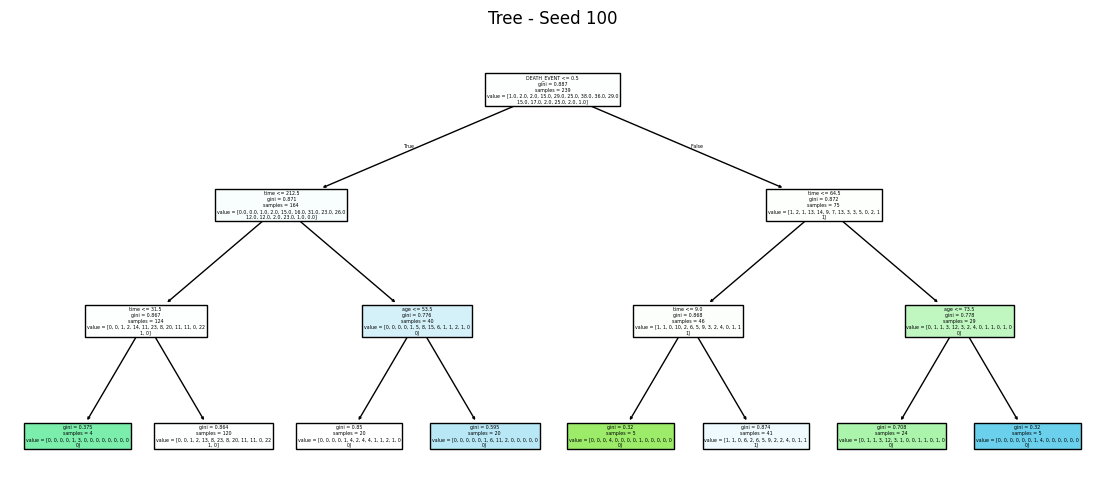

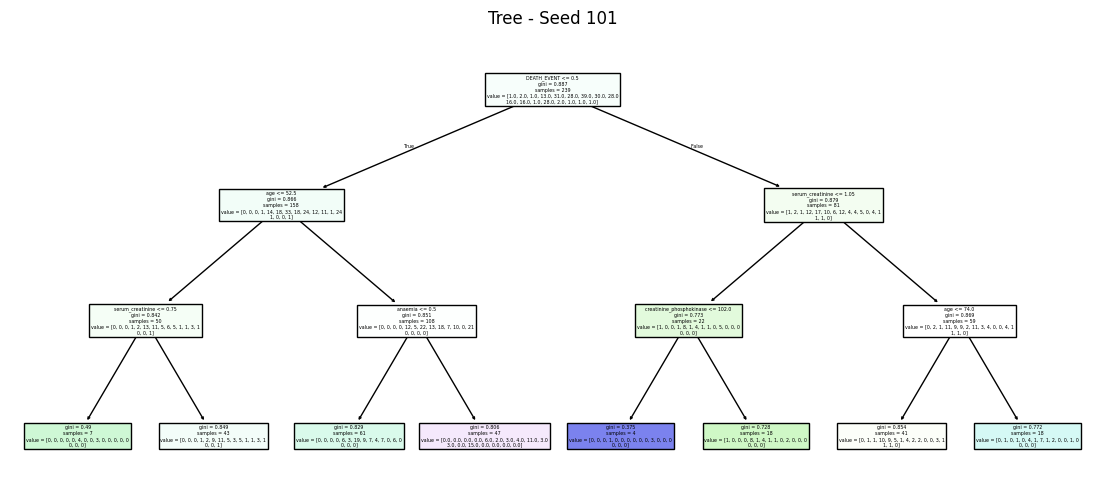

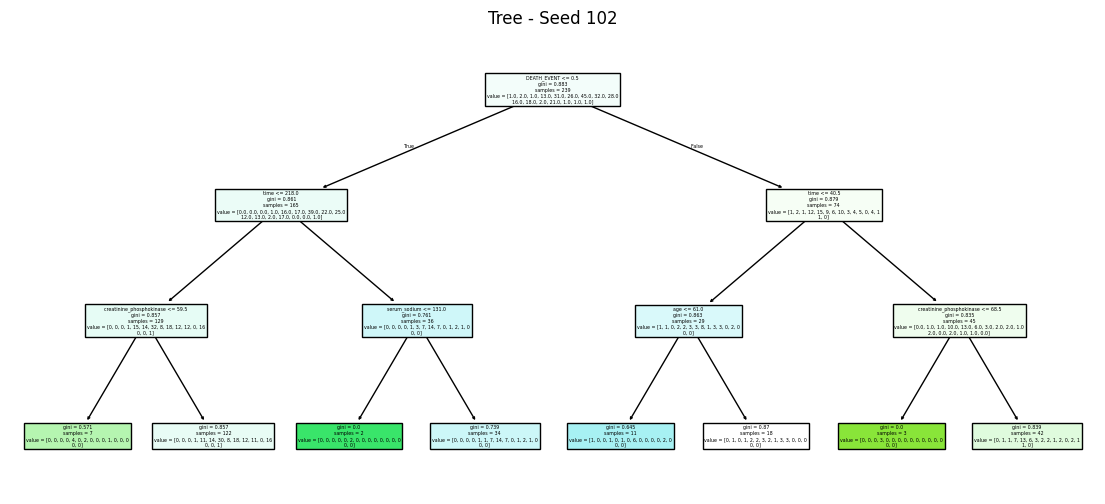

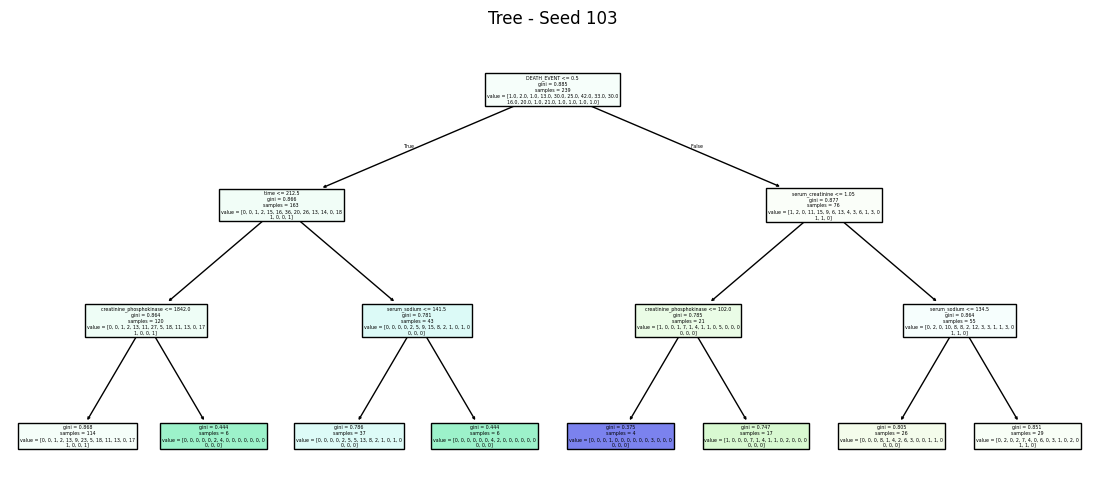

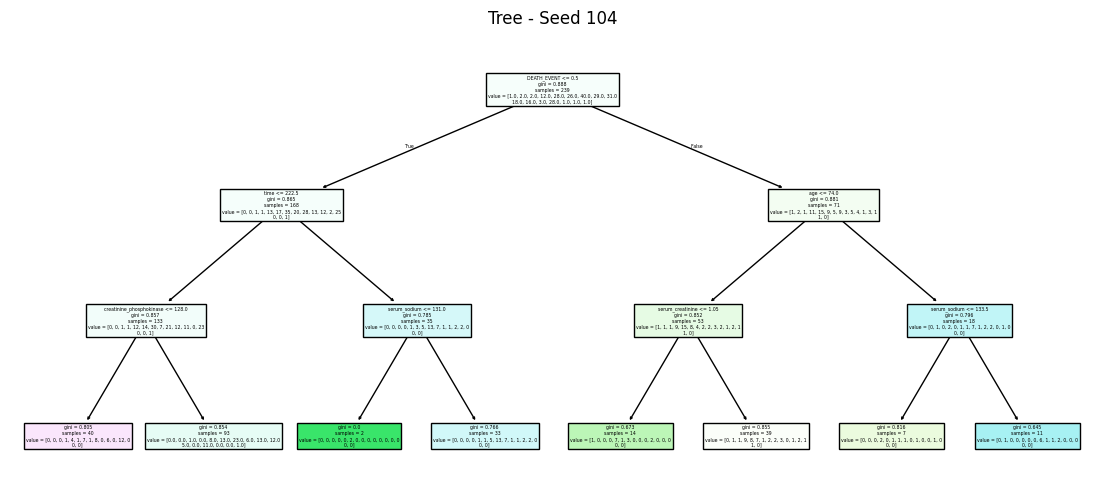

In [163]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))
plot_tree(tree_model, feature_names=eval_x_raw.columns, filled=True)
plt.title("Tree - Seed 100")
plt.show()

plt.figure(figsize=(14, 6))
plot_tree(tree_101, feature_names=eval_x_raw.columns, filled=True)
plt.title("Tree - Seed 101")
plt.show()

plt.figure(figsize=(14, 6))
plot_tree(tree_102, feature_names=eval_x_raw.columns, filled=True)
plt.title("Tree - Seed 102")
plt.show()
plt.figure(figsize=(14, 6))
plot_tree(tree_103, feature_names=eval_x_raw.columns, filled=True)
plt.title("Tree - Seed 103")
plt.show()

plt.figure(figsize=(14, 6))
plot_tree(tree_104, feature_names=eval_x_raw.columns, filled=True)
plt.title("Tree - Seed 104")
plt.show()

In [164]:
# How different are the linear model coefficients?
# Some coefficients stay fairly similar across seeds 101–104, while others
# change more or change signs.
# For example, the DEATH_EVENT coefficient stays negative, ranging from
# -9.8647 to -8.5121.
# The anaemia coefficient is positive for seeds 101, 103, and 104,
# but negative for seed 102.

# How different are the trees?
# The trees for seeds 100–103 all start with DEATH_EVENT, but their
# lower branches change across the different train-test splits.
# For example, the left branch uses time for seed 100,
# high_blood_pressure for seed 101, and serum_creatinine for seed 102.
# Seed 103 also uses time, but splits at a different value than seed 100.


4. Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

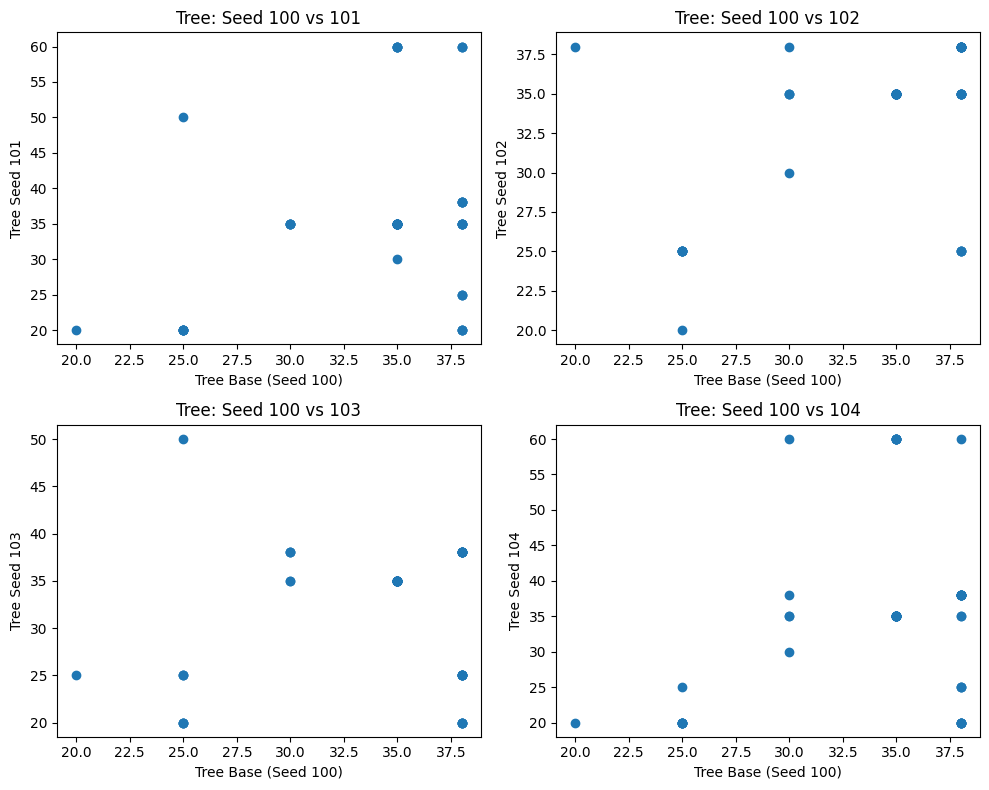

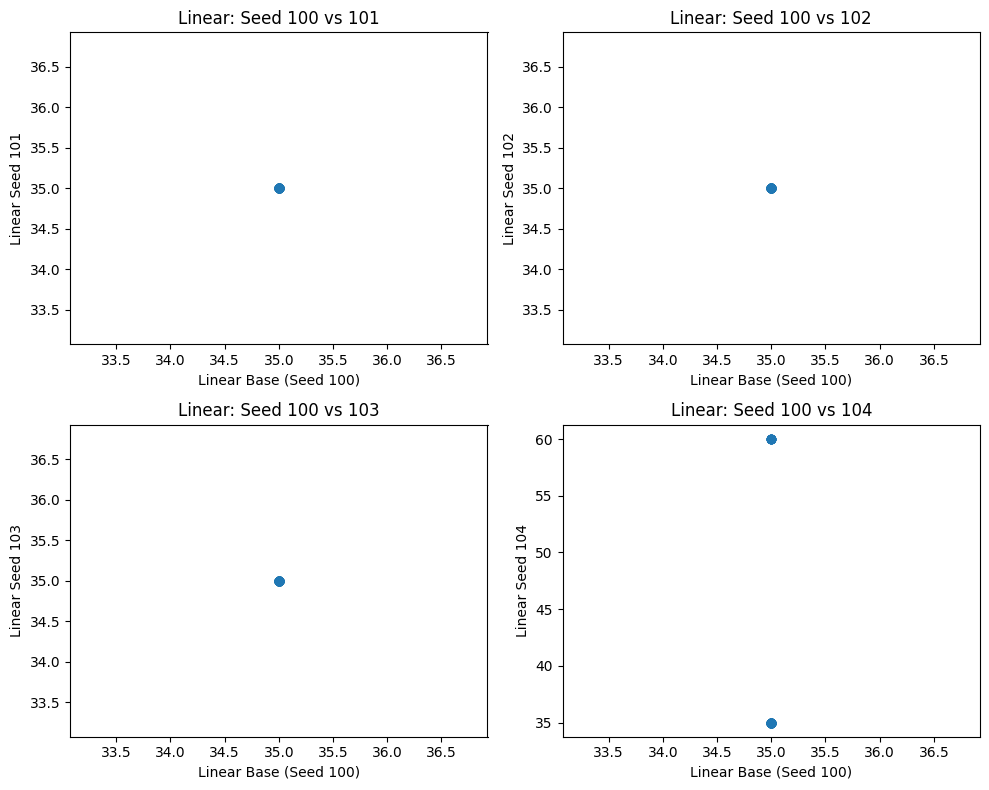

In [171]:
#a
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

plt.subplot(2, 2, 1)
plt.scatter(tree_preds_base, tree_preds_101)
plt.xlabel("Tree Base (Seed 100)")
plt.ylabel("Tree Seed 101")
plt.title("Tree: Seed 100 vs 101")

plt.subplot(2, 2, 2)
plt.scatter(tree_preds_base, tree_preds_102)
plt.xlabel("Tree Base (Seed 100)")
plt.ylabel("Tree Seed 102")
plt.title("Tree: Seed 100 vs 102")

plt.subplot(2, 2, 3)
plt.scatter(tree_preds_base, tree_preds_103)
plt.xlabel("Tree Base (Seed 100)")
plt.ylabel("Tree Seed 103")
plt.title("Tree: Seed 100 vs 103")

plt.subplot(2, 2, 4)
plt.scatter(tree_preds_base, tree_preds_104)
plt.xlabel("Tree Base (Seed 100)")
plt.ylabel("Tree Seed 104")
plt.title("Tree: Seed 100 vs 104")

plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 8))

plt.subplot(2, 2, 1)
plt.scatter(lin_preds_base, lin_preds_101)
plt.xlabel("Linear Base (Seed 100)")
plt.ylabel("Linear Seed 101")
plt.title("Linear: Seed 100 vs 101")

plt.subplot(2, 2, 2)
plt.scatter(lin_preds_base, lin_preds_102)
plt.xlabel("Linear Base (Seed 100)")
plt.ylabel("Linear Seed 102")
plt.title("Linear: Seed 100 vs 102")

plt.subplot(2, 2, 3)
plt.scatter(lin_preds_base, lin_preds_103)
plt.xlabel("Linear Base (Seed 100)")
plt.ylabel("Linear Seed 103")
plt.title("Linear: Seed 100 vs 103")

plt.subplot(2, 2, 4)
plt.scatter(lin_preds_base, lin_preds_104)
plt.xlabel("Linear Base (Seed 100)")
plt.ylabel("Linear Seed 104")
plt.title("Linear: Seed 100 vs 104")

plt.tight_layout()
plt.show()



In [172]:
# Do they appear reasonably similar?
# The linear model predictions look pretty similar across seeds since the points follow upward
# trend. The decision tree scatterplots are way more spread out and scattered

In [173]:
#b
#use the EDA slide dont know if it right for correlation though
tree_df = pd.DataFrame({
    "Base_100": tree_preds_base,
    "Seed_101": tree_preds_101,
    "Seed_102": tree_preds_102,
    "Seed_103": tree_preds_103,
    "Seed_104": tree_preds_104
})
print("Tree Correlations:")
print(tree_df.corr().round(4))

lin_df = pd.DataFrame({
    "Base_100": lin_preds_base,
    "Seed_101": lin_preds_101,
    "Seed_102": lin_preds_102,
    "Seed_103": lin_preds_103,
    "Seed_104": lin_preds_104
})
print("\nLinear Model Correlations:")
print(lin_df.corr().round(4))

Tree Correlations:
          Base_100  Seed_101  Seed_102  Seed_103  Seed_104
Base_100    1.0000    0.3490    0.5361    0.1661    0.3057
Seed_101    0.3490    1.0000    0.2422    0.5890    0.5340
Seed_102    0.5361    0.2422    1.0000    0.3837    0.3634
Seed_103    0.1661    0.5890    0.3837    1.0000    0.5593
Seed_104    0.3057    0.5340    0.3634    0.5593    1.0000

Linear Model Correlations:
          Base_100  Seed_101  Seed_102  Seed_103  Seed_104
Base_100       NaN       NaN       NaN       NaN       NaN
Seed_101       NaN       NaN       NaN       NaN       NaN
Seed_102       NaN       NaN       NaN       NaN       NaN
Seed_103       NaN       NaN       NaN       NaN       NaN
Seed_104       NaN       NaN       NaN       NaN       1.0


In [174]:
# Are they highly correlated or not?
# The linear model predictions are strongly correlated with the base model across all seeds: 0.8974, 0.9014, 0.8113, and 0.8023.
# This shows that the linear model predictions tend to move together even when the train-test split changes.

# The decision tree correlations with the base tree are lower 0.3915, 0.3855, 0.4020, and 0.4652.
# This shows that the tree predictions are less strongly related to the base tree's predictions when the split changes.

In [175]:
#C


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [176]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]